# Task 5: Travel-timing recommendation system

This notebook recommends **when** to travel on the single corridor, not which route to take. It uses historical hourly traffic volumes from 2012-2018; it is **not a live forecast or a safety prediction**.

### Before you start
1. From the repository root, run `python Part-3/prepare_labels.py` if the Part 3 labelled dataset is missing (the Part 2 feature dataset must already exist).
2. Run `python Part-3/recommendation_engine.py` to generate or refresh the chart and tables used below.
3. Open this notebook with a Python kernel and **run all cells in order**. The kernel can start in the repository root, `Part-3`, or `Part-3/notebooks`.

The notebook reads the saved chart and tables without rewriting them. Refresh them after changing the input data or engine. See `Part-3/README.md` for dependencies, assumptions and commands.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

# Locate Part-3 whether the kernel starts in the repo root, Part-3, or notebooks.
cwd = Path.cwd()
part_dir = next((p for p in (cwd, cwd / "Part-3", cwd.parent) if (p / "recommendation_engine.py").is_file()), None)
if part_dir is None:
    raise FileNotFoundError("Start the kernel in the repository root, Part-3, or Part-3/notebooks.")
sys.path.insert(0, str(part_dir))
import recommendation_engine as rec

outputs = part_dir / "outputs"
input_file = part_dir / "data" / "processed" / "Metro_Interstate_Traffic_Volume_ml.csv"
required_outputs = ["recommendation_profile.png", "recommendation_windows.csv", "recommendation_backtest.csv", "recommendation_weather_check.csv"]
if not input_file.is_file():
    raise FileNotFoundError(f"Missing {input_file}. Run python Part-3/prepare_labels.py from the repository root.")
missing_outputs = [name for name in required_outputs if not (outputs / name).is_file()]
if missing_outputs:
    raise FileNotFoundError(f"Missing outputs: {', '.join(missing_outputs)}. Run python Part-3/recommendation_engine.py from the repository root.")

# Build the same historical profile used by the command-line recommendation engine.
history = rec.prepare_history(pd.read_csv(input_file))
engine = rec.RecommendationEngine(history)
print(f"{len(history):,} hours, {history['timestamp'].min():%Y-%m-%d} to {history['timestamp'].max():%Y-%m-%d}")
print("Congestion thresholds (vehicles/h, quartiles):", [round(float(t), 1) for t in engine.thresholds])

40,575 hours, 2012-10-02 to 2018-09-30
Congestion thresholds (vehicles/h, quartiles): [1248.5, 3427.0, 4952.0]


## 1. Expected traffic by day type and weather
The black line shows the all-weather average; coloured lines show estimates for each weather group. The green band marks the lowest-volume one-hour window within the default 06:00-19:00 range. That range is a configurable assumption, not a finding about when everyone can travel.

Each weather-specific estimate combines the historical mean for that day type, weather group and hour with the all-weather mean. The shrinkage strength of 10 hours is a heuristic, not a validated threshold.

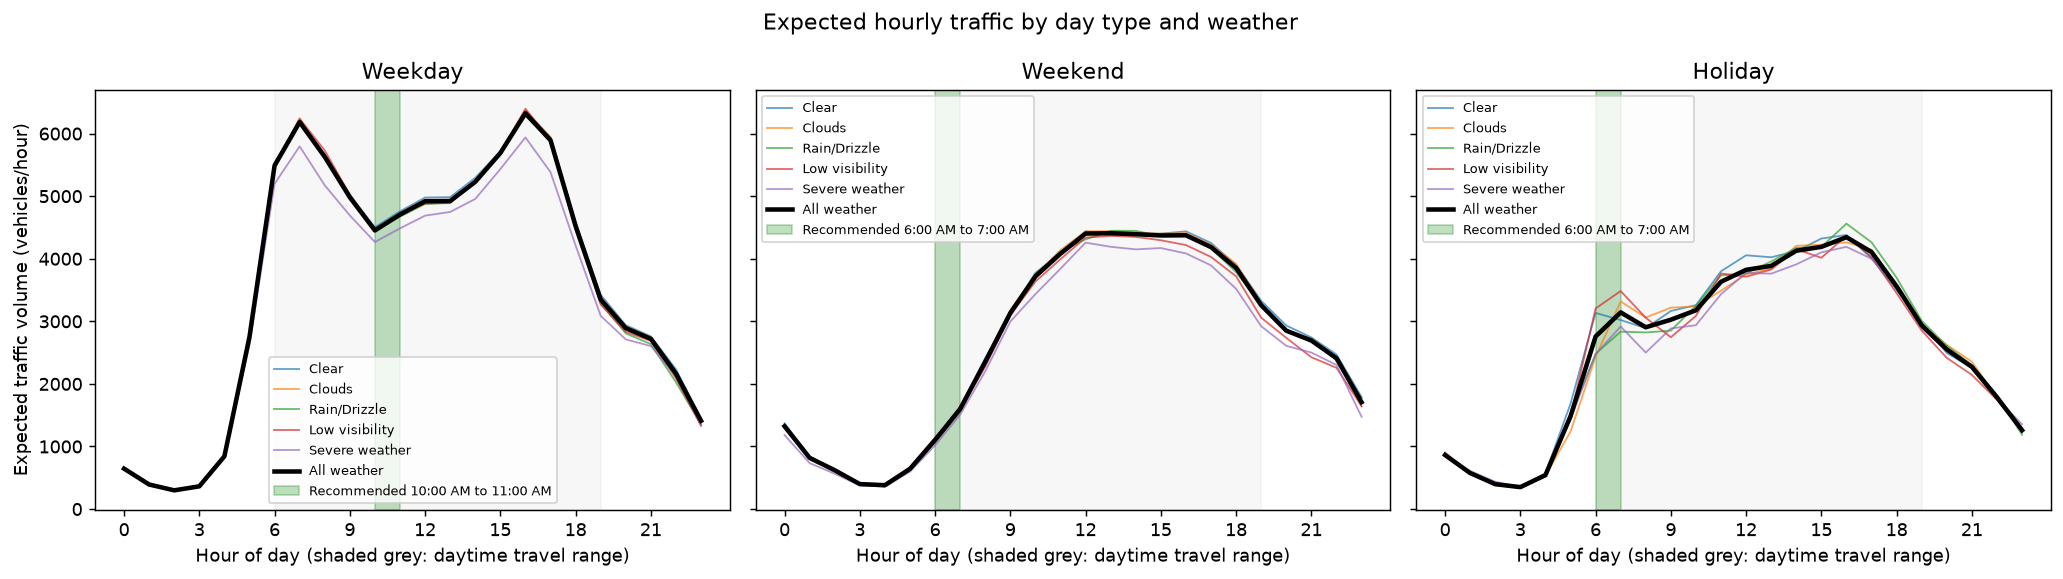

In [2]:
display(Image(filename=str(outputs / "recommendation_profile.png")))

## 2. Example recommendations

The four examples below cover a weekday, rainy weather, a weekend, and a holiday/event day in severe weather. `Any` uses all weather conditions together; the holiday/event category also includes the source's State Fair flag. Each result gives a suggested window, its estimated volume and a comparison with the busiest window.

A sparse-weather warning means that few relevant observations are available; treat that recommendation cautiously. An optional later window is explicitly outside the requested range.

In [3]:
import textwrap

# Each tuple is (day type, weather group, journey duration in hours).
examples = [
    ("Weekday", "Any", 1),
    ("Weekday", "Rain/Drizzle", 2),
    ("Weekend", "Clear", 1),
    ("Holiday", "Severe weather", 1),
]
for day_type, weather, duration in examples:
    result = engine.recommend(day_type, weather, duration)
    print(f"[{day_type} | {weather} | {duration} h]")
    print(textwrap.fill(result.text, 110), "\n")

Holiday / Severe weather 06:00-07:00 rests on as few as 5 historical hours.


[Weekday | Any | 1 h]
For a weekday journey, consider travelling between 10:00 AM and 11:00 AM, when historical traffic volumes are
typically lower (about 4,453 vehicles per hour, 'High' on this corridor's four-level congestion scale). This
is the quietest option in the travel range, but volumes are still relatively high. That is about 30% less than
the busiest period, 4:00 PM to 5:00 PM (about 6,325 vehicles per hour). Other good options: 6:00 PM to 7:00 PM
(about 4,525); 11:00 AM to 12:00 PM (about 4,707). If you can travel later, outside your requested range, 9:00
PM to 10:00 PM is lighter still (about 2,720 vehicles per hour). This is based on historical hourly volumes on
this corridor for travel between 6:00 AM and 7:00 PM; it is not a live forecast. 

[Weekday | Rain/Drizzle | 2 h]
For a weekday journey in rainy or drizzly weather, consider travelling between 10:00 AM and 12:00 PM, when
historical traffic volumes are typically lower (about 4,560 vehicles per hour, 'High' on this 

### Try your own journey

Change the values below and rerun the cell. `day_type` accepts `Weekday`, `Weekend`, or `Holiday`; `weather` accepts `Any`, `Clear`, `Clouds`, `Rain/Drizzle`, `Low visibility`, or `Severe weather`. `duration` is 1-6 whole hours. Set `earliest` and `latest` in 24-hour time; the journey must fit between them. The optional later suggestion, if shown, is outside that range.

In [4]:
# Example: a two-hour weekday journey in rain, ending by 5 PM.
day_type = "Weekday"
weather = "Rain/Drizzle"
duration = 2
earliest = 7  # 7:00 AM, earliest possible start
latest = 17   # 5:00 PM, latest possible end

custom = engine.recommend(day_type, weather, duration, earliest, latest)
print(textwrap.fill(custom.text, 110))

For a weekday journey in rainy or drizzly weather, consider travelling between 10:00 AM and 12:00 PM, when
historical traffic volumes are typically lower (about 4,560 vehicles per hour, 'High' on this corridor's four-
level congestion scale). This is the quietest option in the travel range, but volumes are still relatively
high. That is about 24% less than the busiest period, 3:00 PM to 5:00 PM (about 5,996 vehicles per hour).
Other good options: 12:00 PM to 2:00 PM (about 4,883); 8:00 AM to 10:00 AM (about 5,349). If you can travel
later, outside your requested range, 8:00 PM to 10:00 PM is lighter still (about 2,722 vehicles per hour). The
weather-adjusted historical estimate differs from the all-weather average by under 5% at this time. This is
based on historical hourly volumes on this corridor for travel between 7:00 AM and 5:00 PM; it is not a live
forecast.


## 3. Recommended 1-hour window for every scenario

Read across a row to compare day types for the same weather. These saved results use the default 06:00-19:00 search range.

In [5]:
windows = pd.read_csv(outputs / "recommendation_windows.csv")
one_hour = windows[windows["duration_hours"] == 1]
one_hour.pivot(index="weather", columns="day_type", values="window")

day_type,Holiday,Weekday,Weekend
weather,,,
Any,6:00 AM to 7:00 AM,10:00 AM to 11:00 AM,6:00 AM to 7:00 AM
Clear,8:00 AM to 9:00 AM,10:00 AM to 11:00 AM,6:00 AM to 7:00 AM
Clouds,6:00 AM to 7:00 AM,10:00 AM to 11:00 AM,6:00 AM to 7:00 AM
Low visibility,9:00 AM to 10:00 AM,10:00 AM to 11:00 AM,6:00 AM to 7:00 AM
Rain/Drizzle,6:00 AM to 7:00 AM,10:00 AM to 11:00 AM,6:00 AM to 7:00 AM
Severe weather,6:00 AM to 7:00 AM,6:00 PM to 7:00 PM,6:00 AM to 7:00 AM


For these one-hour scenarios, the weather-adjusted estimates differ from the all-weather estimates by less than 8% for weekdays and weekends. Some Holiday weather cells have few observations, so `limited_evidence` is True. These are associations, not causal effects:

In [6]:
one_hour[one_hour["weather"] != "Any"][["day_type", "weather", "window", "expected_volume", "weather_vs_all_pct", "min_weather_hours", "limited_evidence"]]

,day_type,weather,window,expected_volume,weather_vs_all_pct,min_weather_hours,limited_evidence
3,Weekday,Clear,10:00 AM to 11:00 AM,4503,1.1,346.0,False
6,Weekday,Clouds,10:00 AM to 11:00 AM,4461,0.2,447.0,False
9,Weekday,Rain/Drizzle,10:00 AM to 11:00 AM,4447,-0.1,152.0,False
12,Weekday,Low visibility,10:00 AM to 11:00 AM,4436,-0.4,134.0,False
15,Weekday,Severe weather,6:00 PM to 7:00 PM,4213,-6.9,79.0,False
21,Weekend,Clear,6:00 AM to 7:00 AM,1116,1.2,171.0,False
24,Weekend,Clouds,6:00 AM to 7:00 AM,1101,-0.2,133.0,False
27,Weekend,Rain/Drizzle,6:00 AM to 7:00 AM,1071,-2.9,60.0,False
30,Weekend,Low visibility,6:00 AM to 7:00 AM,1143,3.6,80.0,False
33,Weekend,Severe weather,6:00 AM to 7:00 AM,1019,-7.6,30.0,False


## 4. Backtest on the last 20% of hours
The profile is rebuilt from the first 80% of hours (as in Tasks 1-3), then checked against fully observed days in the remaining 20%, starting on 2017-10-26. `test_days` is the number of complete days; volumes are vehicles per hour. A higher `days_below_daytime_average_pct` means the recommended window was below that day's average more often. The final recommendations above use all available history, including this test period.

In [7]:
backtest = pd.read_csv(outputs / "recommendation_backtest.csv")
backtest[["day_type", "duration_hours", "recommended_window", "test_days", "recommended_actual_mean", "peak_actual_mean", "daytime_actual_mean", "reduction_vs_peak_pct", "days_below_daytime_average_pct"]]

,day_type,duration_hours,recommended_window,test_days,recommended_actual_mean,peak_actual_mean,daytime_actual_mean,reduction_vs_peak_pct,days_below_daytime_average_pct
0,Weekday,1,10:00 AM to 11:00 AM,229,4473,6415,5288,30.3,99.6
1,Weekday,2,10:00 AM to 12:00 PM,229,4586,6131,5288,25.2,99.6
2,Weekday,3,10:00 AM to 1:00 PM,229,4693,5990,5288,21.7,97.4
3,Weekend,1,6:00 AM to 7:00 AM,97,1123,4452,3582,74.8,100.0
4,Weekend,2,6:00 AM to 8:00 AM,97,1369,4450,3582,69.2,100.0
5,Weekend,3,6:00 AM to 9:00 AM,97,1711,4447,3582,61.5,100.0
6,Holiday,1,6:00 AM to 7:00 AM,10,2476,4172,3409,40.7,70.0
7,Holiday,2,8:00 AM to 10:00 AM,10,2768,4090,3409,32.3,80.0
8,Holiday,3,6:00 AM to 9:00 AM,10,2651,4038,3409,34.3,70.0


Does knowing the weather improve the hourly estimate? Mean absolute error on the test hours, with and without the weather group:

In [8]:
pd.read_csv(outputs / "recommendation_weather_check.csv")

,weather_group,test_hours,mae_without_weather,mae_with_weather
0,All,8115,306.2,303.2
1,Clear,2849,296.6,295.7
2,Clouds,2543,298.9,297.1
3,Low visibility,864,240.2,240.5
4,Rain/Drizzle,1003,238.7,235.5
5,Severe weather,856,505.1,489.3


**Reading the results.** Using observed test-hour weather reduces hourly error by about 1% overall, with the largest reduction in the severe-weather group. Holiday results rest on 10 test days and some sparse weather cells, so treat them as indicative. Holiday includes the source's State Fair flag. These historical estimates are not evidence of causation, safety or real-time conditions; the recommender does not load the trained models.